# SS3 Part B: Applying the SS2 Logistic Regression Method

## Purpose
This notebook applies the final modelling method selected in SS2, logistic regression, to the STADIOEquities client data. The goal is to predict whether a newly registered client makes a deposit within 30 days, using only information available by the end of day 3.

The notebook is organised into the required assessment components. Run the cells from top to bottom. Inspect the outputs and write your own brief interpretation where prompted.

## 1. Setup and imports

In [3]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    classification_report,
)

pd.set_option("display.max_columns", 100)

# This notebook expects the five CSV files inside a folder named data.
DATA_DIR = Path("data")

if not DATA_DIR.exists():
    DATA_DIR = Path("CAP182_SS3_Client_Data") / "data"

print("Data folder:", DATA_DIR.resolve())
print("CSV files:", sorted(p.name for p in DATA_DIR.glob("*.csv")))


Data folder: C:\Users\cash\Downloads\stadioequities\stadioequities\data
CSV files: ['table1_client_demographics_registration.csv', 'table2_onboarding_kyc_day3.csv', 'table3_app_web_behaviour_day3.csv', 'table4_funding_account_status.csv', 'table5_marketing_acquisition.csv']


## 2. Data inventory

In [4]:
files = {
    "table1": "table1_client_demographics_registration.csv",
    "table2": "table2_onboarding_kyc_day3.csv",
    "table3": "table3_app_web_behaviour_day3.csv",
    "table4": "table4_funding_account_status.csv",
    "table5": "table5_marketing_acquisition.csv",
}

tables = {}
for name, filename in files.items():
    df = pd.read_csv(DATA_DIR / filename)
    tables[name] = df
    print(f"\\n{'='*80}\\n{name}: {filename}")
    print("Shape (rows, columns):", df.shape)
    print("\\nColumn information:")
    df.info()
    print("\\nNull counts:")
    display(df.isna().sum().to_frame("null_count"))
    print("Fully duplicated rows:", df.duplicated().sum())
    print("Repeated client_id values:", df["client_id"].duplicated().sum())

\n================================================================================\ntable1: table1_client_demographics_registration.csv
Shape (rows, columns): (24259, 7)
\nColumn information:
<class 'pandas.DataFrame'>
RangeIndex: 24259 entries, 0 to 24258
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   client_id               24259 non-null  str    
 1   registration_date       24259 non-null  str    
 2   age                     24106 non-null  float64
 3   province                24259 non-null  str    
 4   stated_investment_goal  23553 non-null  str    
 5   stated_risk_appetite    24259 non-null  str    
 6   acquisition_channel     24259 non-null  str    
dtypes: float64(1), str(6)
memory usage: 2.7 MB
\nNull counts:


,null_count
client_id,0
registration_date,0
age,153
province,0
stated_investment_goal,706
stated_risk_appetite,0
acquisition_channel,0


Fully duplicated rows: 72
Repeated client_id values: 72
\n================================================================================\ntable2: table2_onboarding_kyc_day3.csv
Shape (rows, columns): (24187, 5)
\nColumn information:
<class 'pandas.DataFrame'>
RangeIndex: 24187 entries, 0 to 24186
Data columns (total 5 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   client_id                        24187 non-null  str    
 1   kyc_status_day3                  24187 non-null  str    
 2   onboarding_steps_completed_day3  24187 non-null  int64  
 3   step_last_abandoned              4610 non-null   str    
 4   time_to_kyc_complete_hours       12063 non-null  float64
dtypes: float64(1), int64(1), str(3)
memory usage: 1.5 MB
\nNull counts:


,null_count
client_id,0
kyc_status_day3,0
onboarding_steps_completed_day3,0
step_last_abandoned,19577
time_to_kyc_complete_hours,12124


Fully duplicated rows: 0
Repeated client_id values: 0
\n================================================================================\ntable3: table3_app_web_behaviour_day3.csv
Shape (rows, columns): (24187, 6)
\nColumn information:
<class 'pandas.DataFrame'>
RangeIndex: 24187 entries, 0 to 24186
Data columns (total 6 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   client_id                       24187 non-null  str    
 1   time_to_first_session_hours     24187 non-null  float64
 2   first_session_duration_minutes  23894 non-null  float64
 3   screens_viewed_first_session    24187 non-null  int64  
 4   sessions_by_day3                24187 non-null  int64  
 5   device_type                     24187 non-null  str    
dtypes: float64(2), int64(2), str(2)
memory usage: 1.5 MB
\nNull counts:


...

Fully duplicated rows: 0
Repeated client_id values: 0
\n================================================================================\ntable4: table4_funding_account_status.csv
Shape (rows, columns): (24187, 4)
\nColumn information:
<class 'pandas.DataFrame'>
RangeIndex: 24187 entries, 0 to 24186
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   client_id                 24187 non-null  str  
 1   deposited_within_30_days  24187 non-null  int64
 2   date_of_first_deposit     10239 non-null  str  
 3   account_status_day30      24187 non-null  str  
dtypes: int64(1), str(3)
memory usage: 1.4 MB
\nNull counts:


,null_count
client_id,0
deposited_within_30_days,0
date_of_first_deposit,13948
account_status_day30,0


Fully duplicated rows: 0
Repeated client_id values: 0
\n================================================================================\ntable5: table5_marketing_acquisition.csv
Shape (rows, columns): (24187, 3)
\nColumn information:
<class 'pandas.DataFrame'>
RangeIndex: 24187 entries, 0 to 24186
Data columns (total 3 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   client_id              24187 non-null  str    
 1   acquisition_cost_zar   24187 non-null  float64
 2   nudge_engagement_day3  24187 non-null  str    
dtypes: float64(1), str(2)
memory usage: 961.0 KB
\nNull counts:


,null_count
client_id,0
acquisition_cost_zar,0
nudge_engagement_day3,0


Fully duplicated rows: 0
Repeated client_id values: 0


### Table descriptions (confirm these against the outputs)
- **Table 1** contains client registration details and demographics, including registration date, age, province, investment goal, risk appetite and acquisition channel. It has more rows than the other tables, so its duplicate records and client IDs need to be investigated before merging.
- **Table 2** contains onboarding and Know Your Customer (KYC) progress measured by day 3.
- **Table 3** contains early app/web behaviour by day 3, such as first-session timing, session duration, screens viewed, session count and device type.
- **Table 4** contains the target `deposited_within_30_days`, as well as later information about deposit date and day-30 account status. The later fields must not be used as predictors.
- **Table 5** contains acquisition cost and day-3 engagement with nudges.

## 3. Compare client ID sets

In [5]:
id_sets = {
    name: set(df["client_id"].dropna())
    for name, df in tables.items()
}

reference_name = "table2"
reference_ids = id_sets[reference_name]
comparison_rows = []

for name, ids in id_sets.items():
    comparison_rows.append({
        "table": name,
        "rows": len(tables[name]),
        "unique_non_null_client_ids": len(ids),
        f"IDs in {name} but not {reference_name}": len(ids - reference_ids),
        f"IDs in {reference_name} but not {name}": len(reference_ids - ids),
        "shared IDs with table2": len(ids & reference_ids),
    })

display(pd.DataFrame(comparison_rows).set_index("table"))

print("Table 1 fully duplicated rows:", tables["table1"].duplicated().sum())
print("Table 1 repeated client IDs:", tables["table1"]["client_id"].duplicated().sum())
print("Table 1 IDs not present in table2:", len(id_sets["table1"] - reference_ids))
print("Table 2 IDs not present in table1:", len(reference_ids - id_sets["table1"]))

# Inspect duplicated records rather than removing them without checking.
display(tables["table1"][tables["table1"].duplicated(keep=False)].sort_values("client_id").head(20))

,rows,unique_non_null_client_ids,IDs in table1 but not table2,IDs in table2 but not table1,shared IDs with table2,IDs in table2 but not table2,IDs in table3 but not table2,IDs in table2 but not table3,IDs in table4 but not table2,IDs in table2 but not table4,IDs in table5 but not table2,IDs in table2 but not table5
table,,,,,,,,,,,,
table1,24259,24187,0.0,0.0,24187,NaN,NaN,NaN,NaN,NaN,NaN,NaN
table2,24187,24187,NaN,NaN,24187,0.0,NaN,NaN,NaN,NaN,NaN,NaN
table3,24187,24187,NaN,NaN,24187,NaN,0.0,0.0,NaN,NaN,NaN,NaN
table4,24187,24187,NaN,NaN,24187,NaN,NaN,NaN,0.0,0.0,NaN,NaN
table5,24187,24187,NaN,NaN,24187,NaN,NaN,NaN,NaN,NaN,0.0,0.0


Table 1 fully duplicated rows: 72
Table 1 repeated client IDs: 72
Table 1 IDs not present in table2: 0
Table 2 IDs not present in table1: 0


,client_id,registration_date,age,province,stated_investment_goal,stated_risk_appetite,acquisition_channel
764,CU-0280764,2026-02-13,22.0,Mpumalanga,Wealth building,Medium,Search ad
24217,CU-0280764,2026-02-13,22.0,Mpumalanga,Wealth building,Medium,Search ad
892,CU-0280892,2024-11-02,25.0,Western Cape,Learning/exploring,High,Social media ad
24247,CU-0280892,2024-11-02,25.0,Western Cape,Learning/exploring,High,Social media ad
1332,CU-0281332,2024-08-10,43.0,Western Cape,Retirement,High,Referral
24193,CU-0281332,2024-08-10,43.0,Western Cape,Retirement,High,Referral
1805,CU-0281805,2025-04-27,28.0,Free State,Wealth building,Medium,Influencer
24210,CU-0281805,2025-04-27,28.0,Free State,Wealth building,Medium,Influencer
3515,CU-0283515,2025-12-15,24.0,Gauteng,Short-term growth,High,Search ad
24190,CU-0283515,2025-12-15,24.0,Gauteng,Short-term growth,High,Search ad


## 4. Data cleaning and merging

In [6]:
# Work on copies so the original loaded tables remain unchanged.
t1 = tables["table1"].copy()
t2 = tables["table2"].copy()
t3 = tables["table3"].copy()
t4 = tables["table4"].copy()
t5 = tables["table5"].copy()

# Standardise whitespace in text columns and IDs.
for df in [t1, t2, t3, t4, t5]:
    df["client_id"] = df["client_id"].astype("string").str.strip()
    for col in df.select_dtypes(include=["object", "string"]).columns:
        df[col] = df[col].astype("string").str.strip()

# Remove exact duplicate rows in Table 1 only after recording their count above.
t1 = t1.drop_duplicates()

# Check if client IDs are unique before merging.
for name, df in {"table1": t1, "table2": t2, "table3": t3, "table4": t4, "table5": t5}.items():
    print(name, "rows:", len(df), "duplicate IDs:", df["client_id"].duplicated().sum())

# Keep one row per client in each table; stop if duplicates remain because they need investigation.
assert all(not df["client_id"].duplicated().any() for df in [t1, t2, t3, t4, t5]), \
    "At least one table still has repeated client_id values. Inspect before merging."

data = t1.merge(t2, on="client_id", how="inner", validate="one_to_one")
data = data.merge(t3, on="client_id", how="inner", validate="one_to_one")
data = data.merge(t4, on="client_id", how="inner", validate="one_to_one")
data = data.merge(t5, on="client_id", how="inner", validate="one_to_one")

data["registration_date"] = pd.to_datetime(data["registration_date"], errors="coerce")
print("Merged shape:", data.shape)
print("Unique clients:", data["client_id"].nunique())
display(data.head())

table1 rows: 24187 duplicate IDs: 0
table2 rows: 24187 duplicate IDs: 0
table3 rows: 24187 duplicate IDs: 0
table4 rows: 24187 duplicate IDs: 0
table5 rows: 24187 duplicate IDs: 0
Merged shape: (24187, 21)
Unique clients: 24187


,client_id,registration_date,age,province,stated_investment_goal,stated_risk_appetite,acquisition_channel,kyc_status_day3,onboarding_steps_completed_day3,step_last_abandoned,time_to_kyc_complete_hours,time_to_first_session_hours,first_session_duration_minutes,screens_viewed_first_session,sessions_by_day3,device_type,deposited_within_30_days,date_of_first_deposit,account_status_day30,acquisition_cost_zar,nudge_engagement_day3
0,CU-0280000,2025-06-21,33.0,Gauteng,Learning/exploring,Low,Organic/direct,Completed,5,<NA>,2.4,0.64,4.9,1,1,Android,0,<NA>,Never funded,110.37,Clicked
1,CU-0280001,2025-09-13,35.0,Free State,Short-term growth,Medium,Social media ad,In Progress,1,<NA>,NaN,0.17,2.9,7,3,iOS,0,<NA>,Never funded,249.39,Opened
2,CU-0280002,2024-12-27,29.0,Northern Cape,Wealth building,Low,Social media ad,Completed,5,<NA>,2.1,0.18,13.5,1,3,Web,1,2025-01-21,Funded then dormant,225.47,Clicked
3,CU-0280003,2026-05-24,38.0,KwaZulu-Natal,Wealth building,Medium,Referral,Completed,5,<NA>,3.1,1.51,6.1,10,3,Web,1,2026-05-25,Funded & active,0.00,Opened
4,CU-0280004,2025-10-05,42.0,Western Cape,Short-term growth,Medium,Search ad,Completed,5,<NA>,9.3,3.54,11.0,8,8,Android,1,2025-11-02,Funded & active,133.36,Opened


In [13]:
%whos

Variable                  Type                 Data/Info
--------------------------------------------------------
ColumnTransformer         ABCMeta              <class 'sklearn.compose._<...>ormer.ColumnTransformer'>
ConfusionMatrixDisplay    type                 <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
DATA_DIR                  WindowsPath          data
GridSearchCV              ABCMeta              <class 'sklearn.model_sel<...>on._search.GridSearchCV'>
LogisticRegression        type                 <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
OneHotEncoder             type                 <class 'sklearn.preproces<...>_encoders.OneHotEncoder'>
Path                      type                 <class 'pathlib.Path'>
Pipeline                  ABCMeta              <class 'sklearn.pipeline.Pipeline'>
PrecisionRecallDisplay    type                 <class 'sklearn.metrics._<...>.PrecisionRecallDisplay'>
RocCurveDisplay           type                 <class 'sklearn.

In [14]:
print(data.columns.tolist())

['client_id', 'registration_date', 'age', 'province', 'stated_investment_goal', 'stated_risk_appetite', 'acquisition_channel', 'kyc_status_day3', 'onboarding_steps_completed_day3', 'step_last_abandoned', 'time_to_kyc_complete_hours', 'time_to_first_session_hours', 'first_session_duration_minutes', 'screens_viewed_first_session', 'sessions_by_day3', 'device_type', 'deposited_within_30_days', 'date_of_first_deposit', 'account_status_day30', 'acquisition_cost_zar', 'nudge_engagement_day3']


In [15]:
print(data["kyc_status_day3"].value_counts(dropna=False))

kyc_status_day3
Completed      12063
In Progress     6412
Abandoned       4610
Not Started     1102
Name: count, dtype: int64[pyarrow]


In [16]:
# Predict a deposit if the client completed KYC by day 3
kyc_pred = (X_test["kyc_status_day3"] == "Completed").astype(int)

# Compare these predictions with the actual test outcomes
print("KYC baseline accuracy:", round(accuracy_score(y_test, kyc_pred), 4))
print("\nKYC baseline classification report:")
print(classification_report(
    y_test,
    kyc_pred,
    target_names=["No deposit within 30 days", "Deposit within 30 days"],
    zero_division=0
))

KYC baseline accuracy: 0.7917

KYC baseline classification report:
                           precision    recall  f1-score   support

No deposit within 30 days       0.87      0.76      0.81      2127
   Deposit within 30 days       0.71      0.84      0.77      1502

                 accuracy                           0.79      3629
                macro avg       0.79      0.80      0.79      3629
             weighted avg       0.80      0.79      0.79      3629



## 5. Define target and predictors

The target is `deposited_within_30_days`. Predictors are restricted to information available by the end of day 3. We exclude `date_of_first_deposit` and `account_status_day30` because these are known only after the prediction point and would leak future information into the model. We also exclude the client identifier because it is an ID, not a meaningful behavioural predictor.

In [8]:
target = "deposited_within_30_days"

# Remove records without a usable target or registration date.
data = data.dropna(subset=[target, "registration_date"]).copy()
data[target] = data[target].astype(int)

excluded = [
    "client_id",
    target,
    "date_of_first_deposit",   # future information / leakage
    "account_status_day30",    # future information / leakage
]
X = data.drop(columns=[c for c in excluded if c in data.columns])

# Use a coarse registration-month feature; keep the raw date only for chronological splitting.
X["registration_month"] = data["registration_date"].dt.month
y = data[target]

print("Instances:", len(data))
print("Target classes:")
display(y.value_counts().rename(index={0: "No deposit within 30 days", 1: "Deposit within 30 days"}).to_frame("count"))
print("Target proportions:")
display(y.value_counts(normalize=True).rename(index={0: "No deposit within 30 days", 1: "Deposit within 30 days"}).to_frame("proportion"))

# Basic age plausibility check: mark values outside 18-100 as missing rather than inventing a replacement.
if "age" in X.columns:
    print("Age values outside 18-100:", int((~X["age"].between(18, 100) & X["age"].notna()).sum()))
    X.loc[~X["age"].between(18, 100), "age"] = np.nan

# Sort chronologically to reduce temporal leakage.
order = np.argsort(data["registration_date"].to_numpy())
X = X.iloc[order].reset_index(drop=True)
y = y.iloc[order].reset_index(drop=True)
ordered_dates = data["registration_date"].iloc[order].reset_index(drop=True)

# Chronological 70/15/15 split: training, validation and final unseen test.
n = len(X)
train_end = int(n * 0.70)
valid_end = int(n * 0.85)
X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
X_valid, y_valid = X.iloc[train_end:valid_end], y.iloc[train_end:valid_end]
X_test, y_test = X.iloc[valid_end:], y.iloc[valid_end:]

print("Train:", X_train.shape, "dates:", ordered_dates.iloc[0], "to", ordered_dates.iloc[train_end-1])
print("Validation:", X_valid.shape, "dates:", ordered_dates.iloc[train_end], "to", ordered_dates.iloc[valid_end-1])
print("Test:", X_test.shape, "dates:", ordered_dates.iloc[valid_end], "to", ordered_dates.iloc[-1])

Instances: 24187
Target classes:


,count
deposited_within_30_days,
No deposit within 30 days,13948
Deposit within 30 days,10239


Target proportions:


,proportion
deposited_within_30_days,
No deposit within 30 days,0.576673
Deposit within 30 days,0.423327


Age values outside 18-100: 17
Train: (16930, 18) dates: 2024-06-01 00:00:00 to 2025-11-27 00:00:00
Validation: (3628, 18) dates: 2025-11-27 00:00:00 to 2026-03-22 00:00:00
Test: (3629, 18) dates: 2026-03-22 00:00:00 to 2026-07-14 00:00:00


## 6. Preprocessing and hyperparameter tuning

In [9]:

# Identify numeric and categorical columns from the training data only.
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

# Convert categorical columns to object dtype and pandas missing values to np.nan.
for split in [X_train, X_valid, X_test]:
    split[categorical_features] = split[categorical_features].astype(object)
    split[categorical_features] = split[categorical_features].where(
        split[categorical_features].notna(), np.nan
    )

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

# Tune regularisation strength using training data only.
pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        solver="liblinear",
        random_state=42
    )),
])

param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__class_weight": [None, "balanced"],
}

# Compare settings using time-ordered cross-validation.
cv = TimeSeriesSplit(n_splits=5)

search = GridSearchCV(
    pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True,
)

search.fit(X_train, y_train)

print("Best training-CV ROC-AUC:", round(search.best_score_, 4))
print("Best parameters:", search.best_params_)

best_model = search.best_estimator_


Best training-CV ROC-AUC: 0.8748
Best parameters: {'model__C': 0.1, 'model__class_weight': None}


### Why these preprocessing and model choices?
- Median imputation is used for numeric missing values because it is less sensitive to extreme values than the mean. Categorical missing values are filled with the most frequent training category.
- One-hot encoding converts categories into numeric indicators; scaling numeric features helps logistic regression optimise coefficients consistently.
- These steps are inside a scikit-learn pipeline, so the imputation, encoding and scaling are fitted on the training folds only.
- Logistic regression matches the final method selected in SS2. The grid tests `C` values of 0.01, 0.1, 1 and 10 and compares unweighted with balanced class weights. `C` controls inverse regularisation strength.
- Time-ordered cross-validation is used within the training period so validation folds occur later than their corresponding training folds.

## 7. Model validation on validation and unseen test subsets

In [10]:
def evaluate_model(model, X_part, y_part, label, threshold=0.5):
    probabilities = model.predict_proba(X_part)[:, 1]
    predictions = (probabilities >= threshold).astype(int)
    metrics = {
        "subset": label,
        "n": len(y_part),
        "accuracy": accuracy_score(y_part, predictions),
        "precision": precision_score(y_part, predictions, zero_division=0),
        "recall": recall_score(y_part, predictions, zero_division=0),
        "f1": f1_score(y_part, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_part, probabilities) if y_part.nunique() == 2 else np.nan,
        "pr_auc_average_precision": average_precision_score(y_part, probabilities) if y_part.nunique() == 2 else np.nan,
        "brier_score": brier_score_loss(y_part, probabilities),
    }
    return metrics, probabilities, predictions

valid_metrics, valid_prob, valid_pred = evaluate_model(best_model, X_valid, y_valid, "Validation")
test_metrics, test_prob, test_pred = evaluate_model(best_model, X_test, y_test, "Unseen test")

results = pd.DataFrame([valid_metrics, test_metrics]).set_index("subset")
display(results.round(4))

print("Unseen test classification report:")
print(classification_report(y_test, test_pred, target_names=["No deposit within 30 days", "Deposit within 30 days"], zero_division=0))

,n,accuracy,precision,recall,f1,roc_auc,pr_auc_average_precision,brier_score
subset,,,,,,,,
Validation,3628,0.7958,0.7381,0.8108,0.7728,0.8710,0.8074,0.1430
Unseen test,3629,0.7991,0.7319,0.8123,0.7700,0.8747,0.8039,0.1398


Unseen test classification report:
                           precision    recall  f1-score   support

No deposit within 30 days       0.86      0.79      0.82      2127
   Deposit within 30 days       0.73      0.81      0.77      1502

                 accuracy                           0.80      3629
                macro avg       0.79      0.80      0.80      3629
             weighted avg       0.80      0.80      0.80      3629



### Interpreting validation
Use the unseen-test results as the final estimate of performance; do not tune the model based on the test results. ROC-AUC measures ranking ability, average precision summarises the precision-recall curve, and the Brier score measures probability prediction error (lower is better). Accuracy alone is not enough because it can hide differences in performance between the two target classes.

## 8. Results visualisation

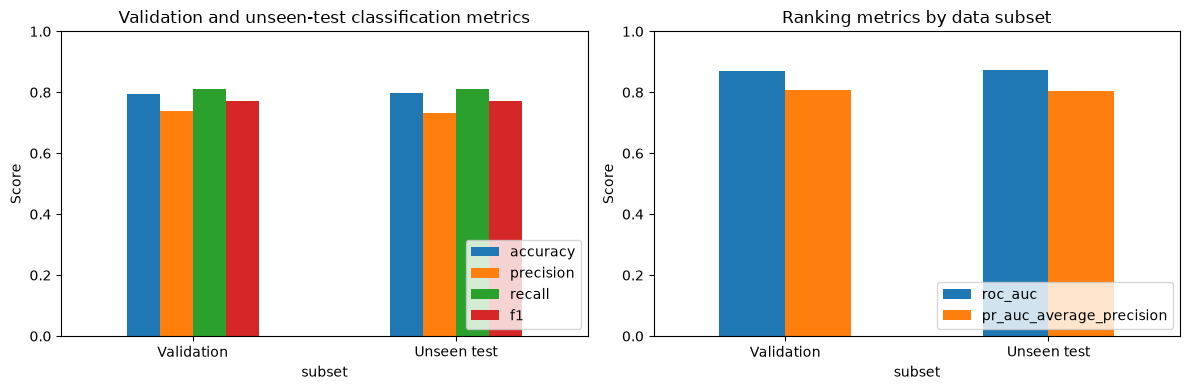

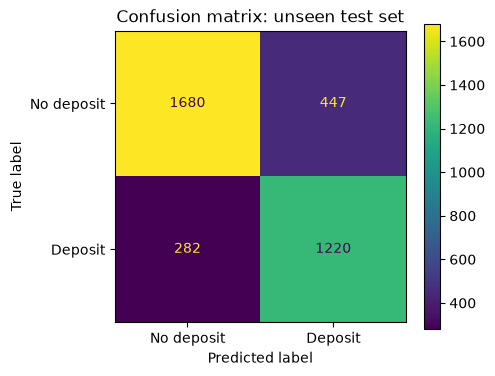

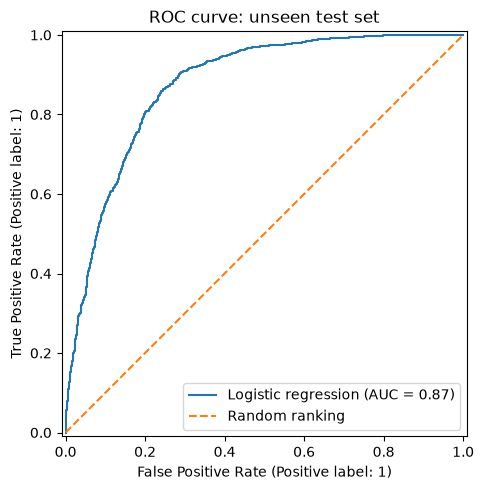

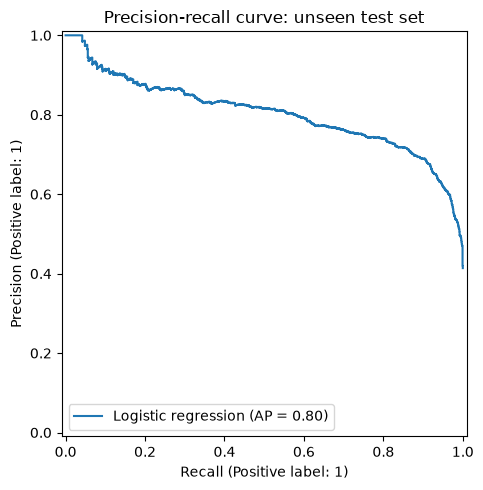

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
results[["accuracy", "precision", "recall", "f1"]].plot(kind="bar", ax=axes[0])
axes[0].set_title("Validation and unseen-test classification metrics")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(loc="lower right")

results[["roc_auc", "pr_auc_average_precision"]].plot(kind="bar", ax=axes[1])
axes[1].set_title("Ranking metrics by data subset")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred,
    display_labels=["No deposit", "Deposit"],
    cmap=None, ax=ax
)
ax.set_title("Confusion matrix: unseen test set")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, test_prob, ax=ax, name="Logistic regression")
ax.plot([0, 1], [0, 1], linestyle="--", label="Random ranking")
ax.set_title("ROC curve: unseen test set")
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_predictions(y_test, test_prob, ax=ax, name="Logistic regression")
ax.set_title("Precision-recall curve: unseen test set")
plt.tight_layout()
plt.show()

## 9. Summary, limitations and next steps

### Summary

The logistic regression model predicts whether a client will deposit within 30 days of registration, using information available by day 3. Hyperparameter tuning selected C = 0.1 and no class weighting, achieving a training cross-validation ROC-AUC of 0.8748. On the unseen test set, the model achieved 79.91% accuracy, 73.19% precision, 81.23% recall, an F1-score of 0.77, a ROC-AUC of 0.8747, an average precision of 0.8039 and a Brier score of 0.1398.

The ROC-AUC indicates that the model can distinguish between depositors and non-depositors reasonably well. The confusion matrix shows that it correctly identified 1,220 of the 1,502 depositors and 1,680 of the 2,127 non-depositors. It incorrectly classified 447 non-depositors as depositors and missed 282 actual depositors. The validation and test results were similar, suggesting consistent performance across the observed periods, although this does not guarantee future stability.

A majority-class baseline that always predicts no deposit would achieve approximately 58.61% accuracy on the test set. The model exceeds this baseline, but it should also be compared with a simple business rule, such as using day-3 KYC completion to identify clients who may need assistance. The results should also be compared with SS2, while recognising that its proxy dataset differs from the STADIOEquities dataset used here.

### Limitations

The dataset contains missing age and stated investment goal values, as well as missing KYC completion times and abandoned-step information. Numeric missing values were handled using median imputation, and categorical missing values were filled using the most frequent category. Seventeen implausible ages outside the range of 18 to 100 were marked as missing. However, some missing KYC and abandonment values may be structural, so future analysis should distinguish these cases where possible.

The model was trained on earlier registration periods and evaluated on later periods, including test registrations from March to July 2026. Changes in client behaviour, marketing channels or onboarding processes could reduce future performance. Age and province were included as predictors, so performance and fairness should be assessed across relevant groups. The model identifies predictive relationships rather than proving that any characteristic causes a deposit. Probability calibration and the practical costs of prediction errors also require further assessment.

### Business application and next steps

The model could help prioritise day-3 onboarding nudges by identifying clients who may need additional support before the 30-day deposit window ends. If the objective is to encourage clients who are unlikely to deposit, lower predicted deposit probabilities could help prioritise outreach. In that case, failing to identify a non-depositor who needs support may be more costly than contacting someone who would have deposited anyway.

The probability threshold should be selected using the validation set, based on the costs of different errors, intervention capacity and the desired balance between precision and recall. The test set should remain reserved for final evaluation. Future work should compare the model with a day-3 KYC-completion baseline, review missing-data patterns, assess calibration and fairness, compare alternative models, and monitor performance on newer registrations.

## 9. Results and Discussion

### 9.1 Model Performance

The logistic regression model was selected using five-fold time-series cross-validation. The best model used a regularisation parameter of C = 0.1 and did not use class weighting. Its mean cross-validation ROC-AUC was 0.8748.

On the unseen test dataset, the model achieved an accuracy of 79.91%, precision of 73.19%, recall of 81.23%, and an F1-score of 77.00%. The ROC-AUC was 0.8747, while the average precision score was 0.8039. The Brier score was 0.1398.

The ROC-AUC indicates that the model is effective at distinguishing between clients who deposit within 30 days and those who do not. The test accuracy is also higher than the majority-class baseline of approximately 58.6%, which predicts that every client will not deposit.

### 9.2 Confusion Matrix

The confusion matrix shows that the model correctly identified 1,220 clients who deposited within 30 days and 1,680 clients who did not deposit. However, it incorrectly predicted that 447 non-depositors would deposit and missed 282 clients who actually deposited.

The recall of 81.23% means the model identified approximately 81% of actual depositors. The results suggest that the model could help identify client behaviour patterns, although its predictions are not always correct.

### 9.3 Limitations and Responsible Use

The dataset contains missing values in fields such as age, stated investment goal, and KYC-related information. Implausible ages were treated as missing, while numerical and categorical missing values were handled using median and most-frequent-value imputation, respectively. This approach may not fully represent structural missingness, such as KYC information that is absent because a client did not complete the process.

The chronological split provides a more realistic assessment of future predictions, but performance may change as client behaviour and acquisition patterns change over time. The model should therefore be monitored before being used in practice.

The model should support, rather than replace, human decision-making. Any use of predictions to guide client engagement should consider fairness across age groups and provinces, protect client information, and avoid unfairly excluding clients based on predicted behaviour.


### 9.4 Comparison with a Simple KYC Baseline

A simple baseline was created by predicting that clients who completed KYC by day 3 would deposit within 30 days, while clients with other KYC statuses would not. On the unseen test dataset, this baseline achieved an accuracy of 79.17%, precision of approximately 71%, recall of approximately 84%, and an F1-score of approximately 77%.

Compared with this baseline, the logistic regression model achieved slightly higher accuracy (79.91%) and precision (73.19%), with a similar F1-score of 77.00%. However, the baseline had higher recall, identifying a larger proportion of actual depositors. This suggests that the logistic regression model provides a modest improvement in overall accuracy and precision, but does not outperform the simple baseline on every metric.

The comparison shows the value of evaluating a machine learning model against a simpler rule rather than relying on accuracy alone.
